In [1]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np

## Data settings

In [2]:
colors = ["#8CBCEA", "#65C59A", "#e2d439", "#EC874C", "#EF8082", "#E094D7", "#D7AC63", "#AC9CF4", "#959C9E"]
conf_colors = colors[:2] + [colors[6]] + [colors[5]]
hdata_path = "../data/curated_data/3string_hobs.pkl"
shots = 300000
hfinal_time = 4.5
hdt = 0.15
tndata_obs_path = "../data/tn/3string/converted_data_3string_BUG_g2.00_m5.00_2x2_dt0.010_Tmax8.00_exp_order30_M00128.txt"
# tndata_obs_path = "../data/tn/3string/IBM_3string_mass_spins_BUG_g2.00_m5.00_ROWS2_COLS2_dt0.010_Tmax3.00_M00128.out"
tndata_corrs_path = "../data/tn/3string/IBM_3string_4mass_correlators_BUG_g2.00_m5.00_ROWS2_COLS2_dt0.010_Tmax3.00_M00128.out"
tnfinal_time = 3
tndt = 0.01
tn_conf_indices = [0, 3, 1, 2]
occupied_qubits = [
    [2, 16, 22, 26],
    [2, 22, 26, 30],
    [2, 14, 22, 26],
    [2, 18, 22, 26],
]

plot_time = 3
hdata_limit = int(np.ceil(plot_time / hdt))+1
tn_data_limit = int(np.ceil(plot_time / tndt))+1

## Load data

In [3]:
import numpy as np
import pickle

with open(hdata_path, "rb") as f:
    data = pickle.load(f)
    hobs = data[0][0]
    hconf = data[1][0]
    hpsamples_sim = data[3][0][0]
    hpsamples_cal = data[3][1][0]

# observables_to_plot = np.load("../data/curated_data/3string_hcorrs.npy")[:hdata_limit, :]
# observables_confidence = np.load("../data/curated_data/3string_hcorrs_conf.npy")[:hdata_limit, :]

tndata_obs = np.loadtxt(tndata_obs_path)
tndata_corrs = np.loadtxt(tndata_corrs_path)

In [4]:
from utils.observables import load_occupation_correlators_bypaulis

occupied_qubits = [
    [2, 16, 22, 26],
    [2, 16],
    [2, 22],
    [2, 26],
    [16, 22],
    [16, 26],
    [22, 26],
    [2, 22, 26, 30],
    [2, 22],
    [2, 26],
    [2, 30],
    [22, 26],
    [22, 30],
    [26, 30],
    [2, 14, 22, 26],
    [2, 14],
    [2, 22],
    [2, 26],
    [14, 22],
    [14, 26],
    [22, 26],
    [2, 18, 22, 26],
    [2, 18],
    [2, 22],
    [2, 26],
    [18, 22],
    [18, 26],
    [22, 26],
]

tn_conf_indices = np.arange(2, 2+len(occupied_qubits))

occupation_operators_vals, occupation_operators_confidence = load_occupation_correlators_bypaulis(hpsamples_sim, occupied_qubits, cal_samples_dicts=hpsamples_cal, confidence=0.7, shots=shots)

labels = [
    r"$\langle" + "".join([r"\tau_{%d}^z" % i for i in st]) + r"\rangle$" for st in occupied_qubits
]

## Plot

In [5]:
def plot_individual_qubits_htn_comparison_to_ax(
    ax, 
    observable_matrix_hardware, 
    observable_matrix_tn, 
    qubit_indices, 
    observable_confidence_hardware=None, 
    x_ticks=None, 
    x_label=None,
    x_ticks_labels=None,
    y_label=None, 
    y_lim=None,
    y_ticks=None,
    labels=None,
    marker="o", 
    cmap=None, 
    title="",
    legend=None
):
    observable_matrix_hardware = np.array(observable_matrix_hardware)[:, qubit_indices]
    observable_matrix_tn = np.array(observable_matrix_tn)[:, qubit_indices]
    if observable_confidence_hardware is not None:
        observable_confidence_hardware = np.array(observable_confidence_hardware)[:, qubit_indices, :]
        if observable_matrix_hardware.shape != observable_confidence_hardware.shape[:-1]:
            raise ValueError("Observable matrix and standard deviation matrix must have the same shape")
    
    if labels is not None:
        if len(labels) != observable_matrix_hardware.shape[1]:
            raise ValueError("labels must have the same length as number of observable")
    
    if cmap is None:
        cmap = plt.get_cmap("Set2")

    if x_ticks is not None:
        if len(x_ticks.shape) == 1:
            ax.set_xticks(x_ticks)
        else:
            ax.set_xticks(*x_ticks)
        x_hardware = np.linspace(x_ticks[0], x_ticks[-1], observable_matrix_hardware.shape[0])
        x_tn = np.linspace(x_ticks[0], x_ticks[-1], observable_matrix_tn.shape[0])
    else:
        x_hardware = np.arange(observable_matrix_hardware.shape[0])
        x_tn = np.arange(observable_matrix_tn.shape[0])

    if labels is None:
        labels = [f"$O_{i}$" for i in range(observable_matrix_hardware.shape[1])]

    hlines = []
    for i in reversed(range(observable_matrix_hardware.shape[1])):
        color = cmap((i % 8))
        ax.plot(x_tn, observable_matrix_tn[:, i], "-", markersize=10, markeredgecolor="black", color=color, label=labels[i], linewidth=3, zorder=2)
        yh = observable_matrix_hardware[:, i]
        if observable_confidence_hardware is not None:
            upper_error_bound_mask = np.less(yh.reshape((len(yh), 1)), observable_confidence_hardware[:, i, :])
            lower_error_bound_mask = np.greater(yh.reshape((len(yh), 1)), observable_confidence_hardware[:, i, :])
            consistency_mask = ~np.logical_xor(np.sum(upper_error_bound_mask, axis=1) == 0, np.sum(lower_error_bound_mask, axis=1) == 0)
            upper_error = observable_confidence_hardware[:, i, 1][consistency_mask] - yh[consistency_mask]
            lower_error = yh[consistency_mask] - observable_confidence_hardware[:, i, 0][consistency_mask]
            yerr = np.zeros_like(upper_error_bound_mask, dtype=float)
            yerr[consistency_mask, 0] = lower_error
            yerr[consistency_mask, 1] = upper_error
            ax.fill_between(x_hardware, observable_confidence_hardware[:, i, 0], observable_confidence_hardware[:, i, 1], color=cmap(i), alpha=0.5)
            hlines.append(ax.plot(x_hardware, observable_matrix_hardware[:, i], marker, markersize=8, markeredgecolor="black", color=color, label=labels[i], zorder=3))
        else:
            hlines.append(ax.plot(x_hardware, observable_matrix_hardware[:, i], marker, markersize=8, markeredgecolor="black", color=color, label=labels[i], zorder=3))
    
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label, labelpad=10)
    ax.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
    if y_lim == "data":
        min_data = np.nanmin(observable_matrix_hardware)
        max_data = np.nanmax(observable_matrix_hardware)
        ax.set_ylim([min_data - 0.05*(max_data - min_data), max_data + 0.05*(max_data - min_data)])
    if x_ticks_labels is not None:
        ax.set_xticks(x_ticks)
        ax.set_xticklabels(x_ticks_labels)
    elif y_lim is not None:
        ax.set_ylim(y_lim)
    if y_ticks is not None:
        ax.set_yticks(y_ticks)
    if title:
        ax.set_title(title, pad=10, fontsize=12)
    if legend:
        ax.legend(handles=[ax.plot([], f"{marker}-", color=cmap(i % 8), markeredgecolor="black")[0] for i in range(observable_matrix_hardware.shape[1])], labels=[line[0].get_label() if isinstance(line, list) else line.get_label() for line in hlines], loc=None, fontsize=12)

def get_lims_from_ticks(ticks, relmargin, y_lim=None):
    if y_lim is not None:
        mask = np.logical_and(ticks >= y_lim[0], ticks <= y_lim[1])
        ticks = ticks[mask]
    min_tick = ticks[0]
    max_tick = ticks[-1]
    delta_ticks = max_tick - min_tick
    return [min_tick - relmargin * delta_ticks, max_tick + relmargin * delta_ticks]

def get_lims_from_ticks(ticks, relmargin, y_lim=None):
    if y_lim is not None:
        mask = np.logical_and(ticks >= y_lim[0], ticks <= y_lim[1])
        ticks = ticks[mask]
    min_tick = ticks[0]
    max_tick = ticks[-1]
    delta_ticks = max_tick - min_tick
    return [min_tick - relmargin * delta_ticks, max_tick + relmargin * delta_ticks]

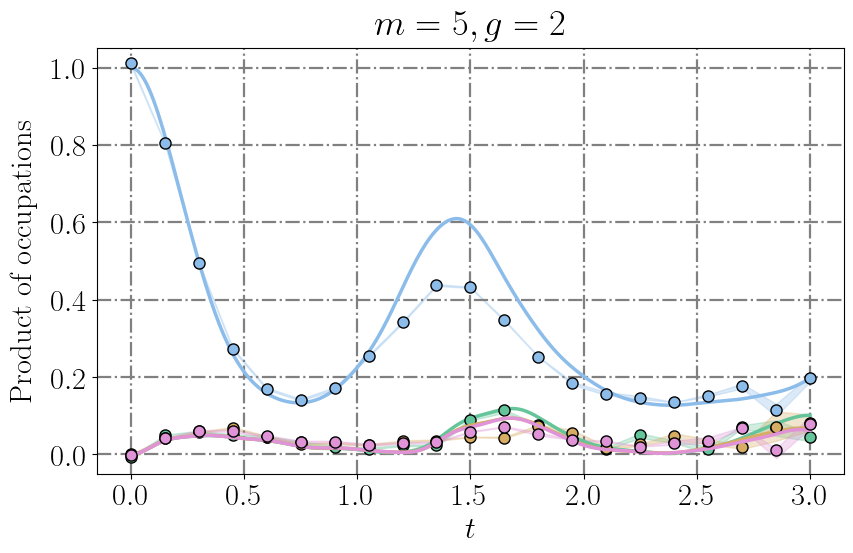

In [6]:
from utils.observables import load_occupation_correlators_bypaulis
from utils.plotting import plot_individual_qubits_htn_comparison

x_ticks = np.linspace(0, plot_time, 7)
x_label = r"$t$"
y_label = r"Product of occupations"
y_lim = [-0.05, 1.05]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = r"$m = 5, g = 2$"
labels = None
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = False

observables_to_plot = occupation_operators_vals[0][:hdata_limit, ::7]
observables_confidence = occupation_operators_confidence[0][:hdata_limit, ::7]

tn_data_to_plot = tndata_corrs[:tn_data_limit, 2::7]

plot_individual_qubits_htn_comparison(observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend, filepath=None)

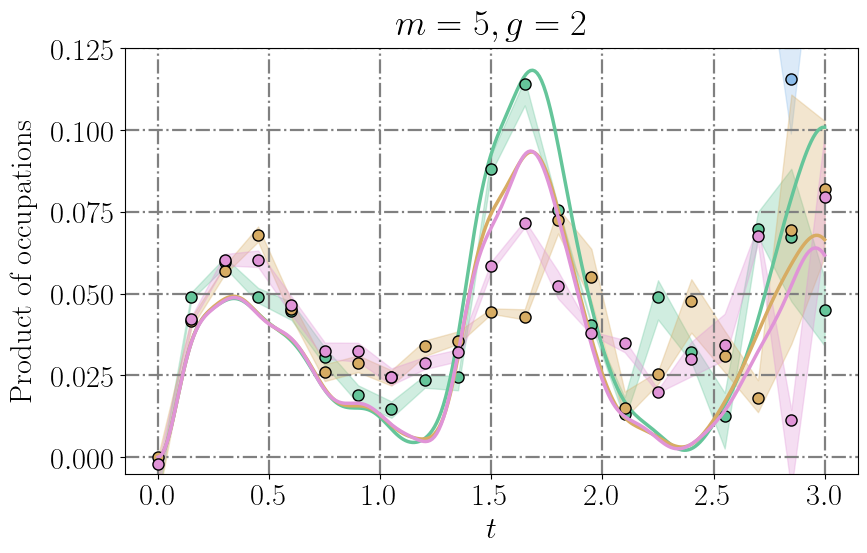

In [7]:
from utils.observables import load_occupation_correlators_bypaulis
from utils.plotting import plot_individual_qubits_htn_comparison

x_ticks = np.linspace(0, plot_time, 7)
x_label = r"$t$"
y_label = r"Product of occupations"
y_lim = [-0.005, 0.125]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = r"$m = 5, g = 2$"
labels = None
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = False

observables_to_plot = occupation_operators_vals[0][:hdata_limit, ::7]
observables_confidence = occupation_operators_confidence[0][:hdata_limit, ::7]

tn_data_to_plot = tndata_corrs[:tn_data_limit, 2::7]

plot_individual_qubits_htn_comparison(observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend, filepath=None)

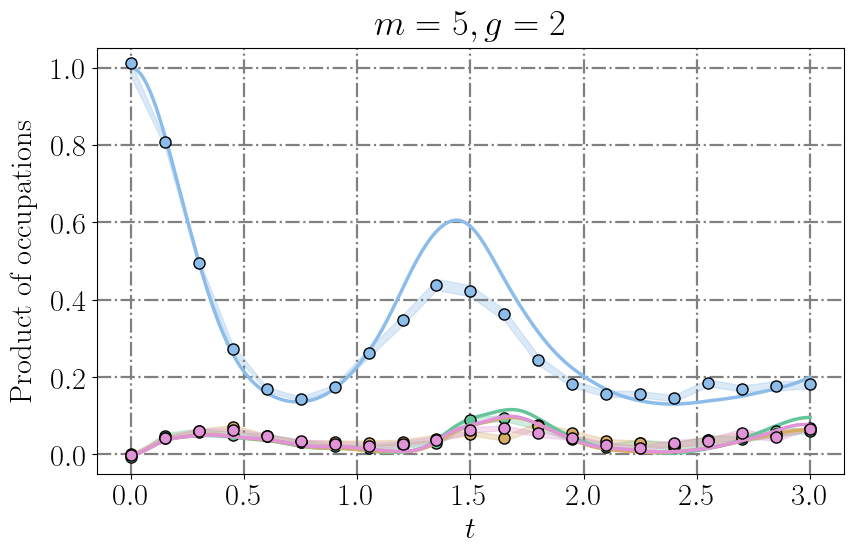

In [8]:
from utils.observables import load_occupation_correlators_bypaulis
from utils.plotting import plot_individual_qubits_htn_comparison

x_ticks = np.linspace(0, plot_time, 7)
x_label = r"$t$"
y_label = r"Product of occupations"
y_lim = [-0.05, 1.05]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = r"$m = 5, g = 2$"
labels = None
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = False

observables_to_plot = occupation_operators_vals[0][:hdata_limit, 1::7] * occupation_operators_vals[0][:hdata_limit, 6::7]
observables_confidence = occupation_operators_confidence[0][:hdata_limit, 1::7] * occupation_operators_confidence[0][:hdata_limit, 6::7]

tn_data_to_plot = tndata_corrs[:tn_data_limit, 3::7] * tndata_corrs[:tn_data_limit, 8::7]

plot_individual_qubits_htn_comparison(observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend, filepath=None)

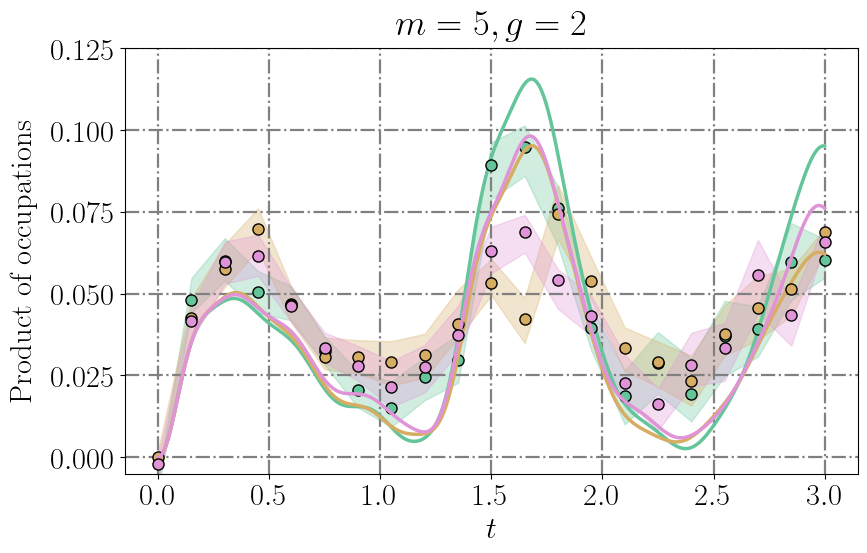

In [9]:
from utils.observables import load_occupation_correlators_bypaulis
from utils.plotting import plot_individual_qubits_htn_comparison

x_ticks = np.linspace(0, plot_time, 7)
x_label = r"$t$"
y_label = r"Product of occupations"
y_lim = [-0.005, 0.125]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = r"$m = 5, g = 2$"
labels = None
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = False

observables_to_plot = occupation_operators_vals[0][:hdata_limit, 1::7] * occupation_operators_vals[0][:hdata_limit, 6::7]
observables_confidence = occupation_operators_confidence[0][:hdata_limit, 1::7] * occupation_operators_confidence[0][:hdata_limit, 6::7]

tn_data_to_plot = tndata_corrs[:tn_data_limit, 3::7] * tndata_corrs[:tn_data_limit, 8::7]

plot_individual_qubits_htn_comparison(observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend, filepath=None)

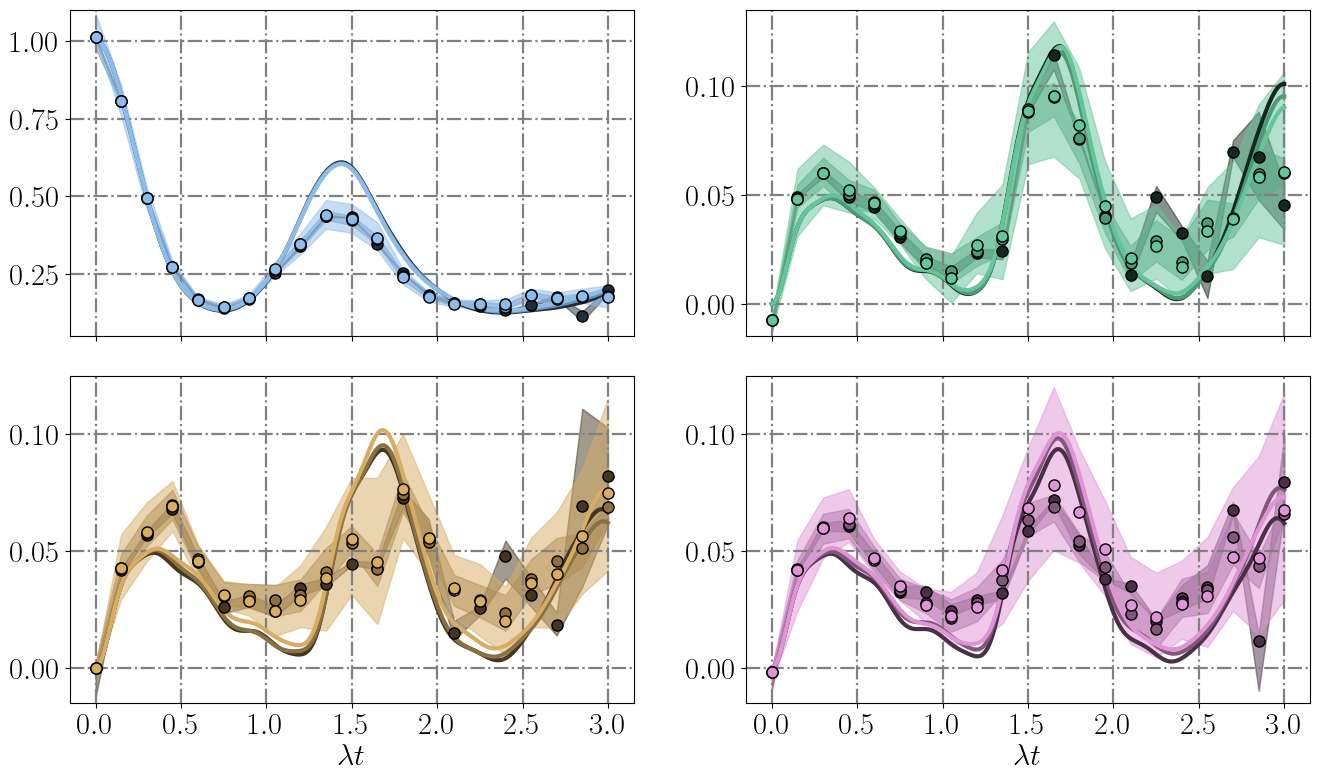

In [ ]:
plt.rc("text", usetex=True)
plt.rc("font", size=22, family="serif", weight="bold")

fig, axs = plt.subplots(2, 2, figsize=[16, 9], sharex=True)
plt.subplots_adjust(hspace=0.12)

x_ticks = np.linspace(0, plot_time, 7)
x_label = None
y_label = None
y_lim = [0.05, 1.1]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = None
labels = [r"$\langle S_1 S_2 S_3 S_4 \rangle$",
          r"$\langle S_1 S_2 \rangle \langle S_3 S_4 \rangle$",
          r"$\langle S_1 \rangle \langle S_2 \rangle \langle S_3 \rangle \langle S_4 \rangle$"]
conf_colors = ["#8CBCEA", "#6990B4", "#222E39"]
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = False

# observables_to_plot = occupation_operators_vals[0][:hdata_limit, 1::7] * occupation_operators_vals[0][:hdata_limit, 6::7]
# observables_confidence = occupation_operators_confidence[0][:hdata_limit, 1::7] * occupation_operators_confidence[0][:hdata_limit, 6::7]

observables_to_plot = np.vstack([
    occupation_operators_vals[0][:hdata_limit, 0],
    occupation_operators_vals[0][:hdata_limit, 1] * occupation_operators_vals[0][:hdata_limit, 6],
    (1 - hobs[:hdata_limit, 2])/2 * (1-hobs[:hdata_limit, 16])/2 * (1-hobs[:hdata_limit, 22])/2 * (1-hobs[:hdata_limit, 26])/2
]).T[:, ::-1]

observables_confidence = np.concatenate([
    occupation_operators_confidence[0][:hdata_limit, 0][:, np.newaxis, :],
    occupation_operators_confidence[0][:hdata_limit, 1][:, np.newaxis, :] * occupation_operators_confidence[0][:hdata_limit, 6][:, np.newaxis, :],
    (1-hconf[:hdata_limit, 2][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 16][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 22][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 26][:, np.newaxis, :])/2
], axis=1)[:, ::-1]

tn_data_to_plot = np.vstack([
    tndata_corrs[:tn_data_limit, 2],
    tndata_corrs[:tn_data_limit, 3] * tndata_corrs[:tn_data_limit, 8],
    (1-tndata_obs[:tn_data_limit-1, 2])/2 * (1-tndata_obs[:tn_data_limit-1, 16])/2 * (1-tndata_obs[:tn_data_limit-1, 22])/2 * (1-tndata_obs[:tn_data_limit-1, 26])/2
]).T[:, ::-1]

plot_individual_qubits_htn_comparison_to_ax(axs[0, 0], observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend)

x_ticks = np.linspace(0, plot_time, 7)
x_label = None
y_label = None
y_lim = [-0.015, 0.135]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = None
labels = [r"$\langle S_1 S_2 S_3 S_4 \rangle$",
          r"$\langle S_1 S_2 \rangle \langle S_3 S_4 \rangle$",
          r"$\langle S_1 \rangle \langle S_2 \rangle \langle S_3 \rangle \langle S_4 \rangle$"]
conf_colors = ["#65C59A", "#4F9978", "#14281F"]
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = False

# observables_to_plot = occupation_operators_vals[0][:hdata_limit, 1::7] * occupation_operators_vals[0][:hdata_limit, 6::7]
# observables_confidence = occupation_operators_confidence[0][:hdata_limit, 1::7] * occupation_operators_confidence[0][:hdata_limit, 6::7]

observables_to_plot = np.vstack([
    occupation_operators_vals[0][:hdata_limit, 7],
    occupation_operators_vals[0][:hdata_limit, 8] * occupation_operators_vals[0][:hdata_limit, 13],
    (1 - hobs[:hdata_limit, 2])/2 * (1-hobs[:hdata_limit, 22])/2 * (1-hobs[:hdata_limit, 26])/2 * (1-hobs[:hdata_limit, 30])/2
]).T[:, ::-1]

observables_confidence = np.concatenate([
    occupation_operators_confidence[0][:hdata_limit, 7][:, np.newaxis, :],
    occupation_operators_confidence[0][:hdata_limit, 8][:, np.newaxis, :] * occupation_operators_confidence[0][:hdata_limit, 13][:, np.newaxis, :],
    (1-hconf[:hdata_limit, 2][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 22][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 26][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 30][:, np.newaxis, :])/2
], axis=1)[:, ::-1]

tn_data_to_plot = np.vstack([
    tndata_corrs[:tn_data_limit, 9],
    tndata_corrs[:tn_data_limit, 10] * tndata_corrs[:tn_data_limit, 15],
    (1-tndata_obs[:tn_data_limit-1, 2])/2 * (1-tndata_obs[:tn_data_limit-1, 22])/2 * (1-tndata_obs[:tn_data_limit-1, 26])/2 * (1-tndata_obs[:tn_data_limit-1, 30])/2
]).T[:, ::-1]

plot_individual_qubits_htn_comparison_to_ax(axs[0, 1], observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend)

####

x_ticks = np.linspace(0, plot_time, 7)
x_label = r"$\lambda t$"
y_label = None
y_lim = [-0.015, 0.125]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = None
labels = [r"$\langle S_1 S_2 S_3 S_4 \rangle$",
          r"$\langle S_1 S_2 \rangle \langle S_3 S_4 \rangle$",
          r"$\langle S_1 \rangle \langle S_2 \rangle \langle S_3 \rangle \langle S_4 \rangle$"]
conf_colors = ["#D7AC63", "#8B7041", "#443720"]
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = False

# observables_to_plot = occupation_operators_vals[0][:hdata_limit, 1::7] * occupation_operators_vals[0][:hdata_limit, 6::7]
# observables_confidence = occupation_operators_confidence[0][:hdata_limit, 1::7] * occupation_operators_confidence[0][:hdata_limit, 6::7]

observables_to_plot = np.vstack([
    occupation_operators_vals[0][:hdata_limit, 14],
    occupation_operators_vals[0][:hdata_limit, 15] * occupation_operators_vals[0][:hdata_limit, 20],
    (1 - hobs[:hdata_limit, 2])/2 * (1-hobs[:hdata_limit, 14])/2 * (1-hobs[:hdata_limit, 22])/2 * (1-hobs[:hdata_limit, 26])/2
]).T[:, ::-1]

observables_confidence = np.concatenate([
    occupation_operators_confidence[0][:hdata_limit, 14][:, np.newaxis, :],
    occupation_operators_confidence[0][:hdata_limit, 15][:, np.newaxis, :] * occupation_operators_confidence[0][:hdata_limit, 20][:, np.newaxis, :],
    (1-hconf[:hdata_limit, 2][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 14][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 22][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 26][:, np.newaxis, :])/2
], axis=1)[:, ::-1]

tn_data_to_plot = np.vstack([
    tndata_corrs[:tn_data_limit, 16],
    tndata_corrs[:tn_data_limit, 17] * tndata_corrs[:tn_data_limit, 22],
    (1-tndata_obs[:tn_data_limit-1, 2])/2 * (1-tndata_obs[:tn_data_limit-1, 14])/2 * (1-tndata_obs[:tn_data_limit-1, 22])/2 * (1-tndata_obs[:tn_data_limit-1, 26])/2
]).T[:, ::-1]

plot_individual_qubits_htn_comparison_to_ax(axs[1, 0], observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend)

#####

x_ticks = np.linspace(0, plot_time, 7)
x_label = r"$\lambda t$"
y_label = None
y_lim = [-0.015, 0.125]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = None
labels = [r"$\langle S_1 S_2 S_3 S_4 \rangle$",
          r"$\langle S_1 S_2 \rangle \langle S_3 S_4 \rangle$",
          r"$\langle S_1 \rangle \langle S_2 \rangle \langle S_3 \rangle \langle S_4 \rangle$"]
conf_colors = ["#E094D7", "#81587C", "#4A3047"]
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = False

# observables_to_plot = occupation_operators_vals[0][:hdata_limit, 1::7] * occupation_operators_vals[0][:hdata_limit, 6::7]
# observables_confidence = occupation_operators_confidence[0][:hdata_limit, 1::7] * occupation_operators_confidence[0][:hdata_limit, 6::7]

observables_to_plot = np.vstack([
    occupation_operators_vals[0][:hdata_limit, 21],
    occupation_operators_vals[0][:hdata_limit, 22] * occupation_operators_vals[0][:hdata_limit, 27],
    (1 - hobs[:hdata_limit, 2])/2 * (1-hobs[:hdata_limit, 18])/2 * (1-hobs[:hdata_limit, 22])/2 * (1-hobs[:hdata_limit, 26])/2
]).T[:, ::-1]

observables_confidence = np.concatenate([
    occupation_operators_confidence[0][:hdata_limit, 21][:, np.newaxis, :],
    occupation_operators_confidence[0][:hdata_limit, 22][:, np.newaxis, :] * occupation_operators_confidence[0][:hdata_limit, 27][:, np.newaxis, :],
    (1-hconf[:hdata_limit, 2][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 18][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 22][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 26][:, np.newaxis, :])/2
], axis=1)[:, ::-1]

tn_data_to_plot = np.vstack([
    tndata_corrs[:tn_data_limit, 23],
    tndata_corrs[:tn_data_limit, 24] * tndata_corrs[:tn_data_limit, 29],
    (1-tndata_obs[:tn_data_limit-1, 2])/2 * (1-tndata_obs[:tn_data_limit-1, 18])/2 * (1-tndata_obs[:tn_data_limit-1, 22])/2 * (1-tndata_obs[:tn_data_limit-1, 26])/2
]).T[:, ::-1]

plot_individual_qubits_htn_comparison_to_ax(axs[1, 1], observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend)

plt.savefig("/results/data_3string_occupation_correlators_comparison.svg")

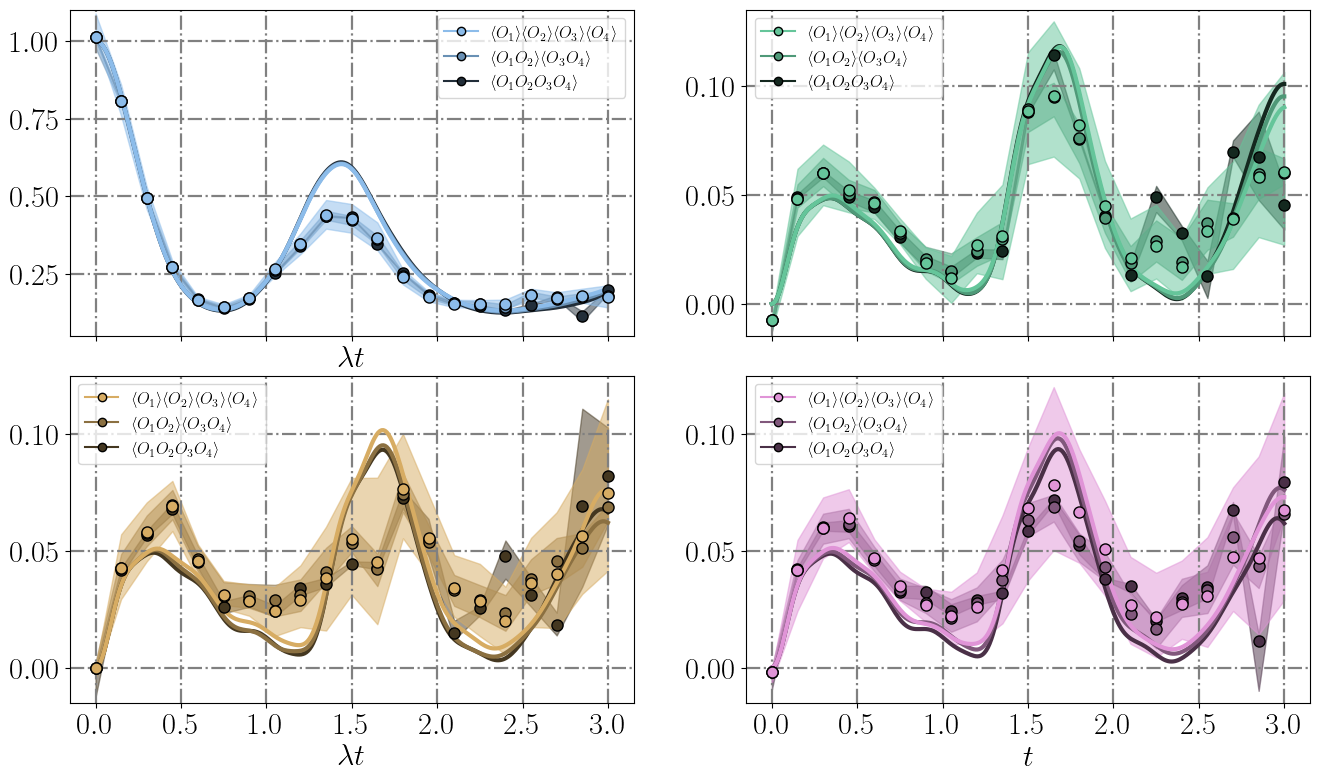

In [ ]:
plt.rc("text", usetex=True)
plt.rc("font", size=22, family="serif", weight="bold")

fig, axs = plt.subplots(2, 2, figsize=[16, 9], sharex=True)
plt.subplots_adjust(hspace=0.12)

x_ticks = np.linspace(0, plot_time, 7)
x_label = r"$\lambda t$"
y_label = None
y_lim = [0.05, 1.1]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = None
labels = [r"$\langle O_1 O_2 O_3 O_4 \rangle$",
          r"$\langle O_1 O_2 \rangle \langle O_3 O_4 \rangle$",
          r"$\langle O_1 \rangle \langle O_2 \rangle \langle O_3 \rangle \langle O_4 \rangle$"]
conf_colors = ["#8CBCEA", "#6990B4", "#222E39"]
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = True

# observables_to_plot = occupation_operators_vals[0][:hdata_limit, 1::7] * occupation_operators_vals[0][:hdata_limit, 6::7]
# observables_confidence = occupation_operators_confidence[0][:hdata_limit, 1::7] * occupation_operators_confidence[0][:hdata_limit, 6::7]

observables_to_plot = np.vstack([
    occupation_operators_vals[0][:hdata_limit, 0],
    occupation_operators_vals[0][:hdata_limit, 1] * occupation_operators_vals[0][:hdata_limit, 6],
    (1 - hobs[:hdata_limit, 2])/2 * (1-hobs[:hdata_limit, 16])/2 * (1-hobs[:hdata_limit, 22])/2 * (1-hobs[:hdata_limit, 26])/2
]).T[:, ::-1]

observables_confidence = np.concatenate([
    occupation_operators_confidence[0][:hdata_limit, 0][:, np.newaxis, :],
    occupation_operators_confidence[0][:hdata_limit, 1][:, np.newaxis, :] * occupation_operators_confidence[0][:hdata_limit, 6][:, np.newaxis, :],
    (1-hconf[:hdata_limit, 2][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 16][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 22][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 26][:, np.newaxis, :])/2
], axis=1)[:, ::-1]

tn_data_to_plot = np.vstack([
    tndata_corrs[:tn_data_limit, 2],
    tndata_corrs[:tn_data_limit, 3] * tndata_corrs[:tn_data_limit, 8],
    (1-tndata_obs[:tn_data_limit-1, 2])/2 * (1-tndata_obs[:tn_data_limit-1, 16])/2 * (1-tndata_obs[:tn_data_limit-1, 22])/2 * (1-tndata_obs[:tn_data_limit-1, 26])/2
]).T[:, ::-1]

plot_individual_qubits_htn_comparison_to_ax(axs[0, 0], observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend)

x_ticks = np.linspace(0, plot_time, 7)
x_label = None
y_label = None
y_lim = [-0.015, 0.135]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = None
labels = [r"$\langle O_1 O_2 O_3 O_4 \rangle$",
          r"$\langle O_1 O_2 \rangle \langle O_3 O_4 \rangle$",
          r"$\langle O_1 \rangle \langle O_2 \rangle \langle O_3 \rangle \langle O_4 \rangle$"]
conf_colors = ["#65C59A", "#4F9978", "#14281F"]
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = True

# observables_to_plot = occupation_operators_vals[0][:hdata_limit, 1::7] * occupation_operators_vals[0][:hdata_limit, 6::7]
# observables_confidence = occupation_operators_confidence[0][:hdata_limit, 1::7] * occupation_operators_confidence[0][:hdata_limit, 6::7]

observables_to_plot = np.vstack([
    occupation_operators_vals[0][:hdata_limit, 7],
    occupation_operators_vals[0][:hdata_limit, 8] * occupation_operators_vals[0][:hdata_limit, 13],
    (1 - hobs[:hdata_limit, 2])/2 * (1-hobs[:hdata_limit, 22])/2 * (1-hobs[:hdata_limit, 26])/2 * (1-hobs[:hdata_limit, 30])/2
]).T[:, ::-1]

observables_confidence = np.concatenate([
    occupation_operators_confidence[0][:hdata_limit, 7][:, np.newaxis, :],
    occupation_operators_confidence[0][:hdata_limit, 8][:, np.newaxis, :] * occupation_operators_confidence[0][:hdata_limit, 13][:, np.newaxis, :],
    (1-hconf[:hdata_limit, 2][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 22][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 26][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 30][:, np.newaxis, :])/2
], axis=1)[:, ::-1]

tn_data_to_plot = np.vstack([
    tndata_corrs[:tn_data_limit, 9],
    tndata_corrs[:tn_data_limit, 10] * tndata_corrs[:tn_data_limit, 15],
    (1-tndata_obs[:tn_data_limit-1, 2])/2 * (1-tndata_obs[:tn_data_limit-1, 22])/2 * (1-tndata_obs[:tn_data_limit-1, 26])/2 * (1-tndata_obs[:tn_data_limit-1, 30])/2
]).T[:, ::-1]

plot_individual_qubits_htn_comparison_to_ax(axs[0, 1], observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend)

####

x_ticks = np.linspace(0, plot_time, 7)
x_label = r"$\lambda t$"
y_label = None
y_lim = [-0.015, 0.125]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = None
labels = [r"$\langle O_1 O_2 O_3 O_4 \rangle$",
          r"$\langle O_1 O_2 \rangle \langle O_3 O_4 \rangle$",
          r"$\langle O_1 \rangle \langle O_2 \rangle \langle O_3 \rangle \langle O_4 \rangle$"]
conf_colors = ["#D7AC63", "#8B7041", "#443720"]
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = True

# observables_to_plot = occupation_operators_vals[0][:hdata_limit, 1::7] * occupation_operators_vals[0][:hdata_limit, 6::7]
# observables_confidence = occupation_operators_confidence[0][:hdata_limit, 1::7] * occupation_operators_confidence[0][:hdata_limit, 6::7]

observables_to_plot = np.vstack([
    occupation_operators_vals[0][:hdata_limit, 14],
    occupation_operators_vals[0][:hdata_limit, 15] * occupation_operators_vals[0][:hdata_limit, 20],
    (1 - hobs[:hdata_limit, 2])/2 * (1-hobs[:hdata_limit, 14])/2 * (1-hobs[:hdata_limit, 22])/2 * (1-hobs[:hdata_limit, 26])/2
]).T[:, ::-1]

observables_confidence = np.concatenate([
    occupation_operators_confidence[0][:hdata_limit, 14][:, np.newaxis, :],
    occupation_operators_confidence[0][:hdata_limit, 15][:, np.newaxis, :] * occupation_operators_confidence[0][:hdata_limit, 20][:, np.newaxis, :],
    (1-hconf[:hdata_limit, 2][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 14][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 22][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 26][:, np.newaxis, :])/2
], axis=1)[:, ::-1]

tn_data_to_plot = np.vstack([
    tndata_corrs[:tn_data_limit, 16],
    tndata_corrs[:tn_data_limit, 17] * tndata_corrs[:tn_data_limit, 22],
    (1-tndata_obs[:tn_data_limit-1, 2])/2 * (1-tndata_obs[:tn_data_limit-1, 14])/2 * (1-tndata_obs[:tn_data_limit-1, 22])/2 * (1-tndata_obs[:tn_data_limit-1, 26])/2
]).T[:, ::-1]

plot_individual_qubits_htn_comparison_to_ax(axs[1, 0], observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend)

#####

x_ticks = np.linspace(0, plot_time, 7)
x_label = "$t$"
y_label = None
y_lim = [-0.015, 0.125]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = None
labels = [r"$\langle O_1 O_2 O_3 O_4 \rangle$",
          r"$\langle O_1 O_2 \rangle \langle O_3 O_4 \rangle$",
          r"$\langle O_1 \rangle \langle O_2 \rangle \langle O_3 \rangle \langle O_4 \rangle$"]
conf_colors = ["#E094D7", "#81587C", "#4A3047"]
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = True

# observables_to_plot = occupation_operators_vals[0][:hdata_limit, 1::7] * occupation_operators_vals[0][:hdata_limit, 6::7]
# observables_confidence = occupation_operators_confidence[0][:hdata_limit, 1::7] * occupation_operators_confidence[0][:hdata_limit, 6::7]

observables_to_plot = np.vstack([
    occupation_operators_vals[0][:hdata_limit, 21],
    occupation_operators_vals[0][:hdata_limit, 22] * occupation_operators_vals[0][:hdata_limit, 27],
    (1 - hobs[:hdata_limit, 2])/2 * (1-hobs[:hdata_limit, 18])/2 * (1-hobs[:hdata_limit, 22])/2 * (1-hobs[:hdata_limit, 26])/2
]).T[:, ::-1]

observables_confidence = np.concatenate([
    occupation_operators_confidence[0][:hdata_limit, 21][:, np.newaxis, :],
    occupation_operators_confidence[0][:hdata_limit, 22][:, np.newaxis, :] * occupation_operators_confidence[0][:hdata_limit, 27][:, np.newaxis, :],
    (1-hconf[:hdata_limit, 2][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 18][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 22][:, np.newaxis, :])/2 * (1-hconf[:hdata_limit, 26][:, np.newaxis, :])/2
], axis=1)[:, ::-1]

tn_data_to_plot = np.vstack([
    tndata_corrs[:tn_data_limit, 23],
    tndata_corrs[:tn_data_limit, 24] * tndata_corrs[:tn_data_limit, 29],
    (1-tndata_obs[:tn_data_limit-1, 2])/2 * (1-tndata_obs[:tn_data_limit-1, 18])/2 * (1-tndata_obs[:tn_data_limit-1, 22])/2 * (1-tndata_obs[:tn_data_limit-1, 26])/2
]).T[:, ::-1]

plot_individual_qubits_htn_comparison_to_ax(axs[1, 1], observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend)

plt.savefig("/results/3string_occupation_correlators_comparison_with_legend.svg")